# Fördjupad modellutvärdering – prognosfel, Bias och höga PM2.5-värden

Denna analys kompletterar den tidigare modellutvärderingen med ett särskilt fokus på prognosfel vid höga PM2.5-koncentrationer och systematiska över- och underskattningar (Bias).

Syftet är att undersöka modellernas styrkor och begränsningar, jämföra deras resultat med persistence baseline och ta fram ett mer nyanserat underlag för val av champion-modell.

Modellerna utvärderas på valideringsdata. Den separata testperioden används först efter modellvalet för en oberoende slututvärdering.

## 1. Data och utvärderingsmetod

Vi använder samma förklarande variabler och tidsuppdelning för samtliga modeller. Prognoshorisonten är sex timmar. Huvudmåttet är **MAE** (genomsnittligt absolut fel, µg/m³). **RMSE** visar känslighet för stora fel, **R²** beskriver förklarad variation och **Bias** visar systematisk över-/underskattning (prognos minus faktiskt värde).

### Avgränsning

Analysen fokuserar på modeller som använder väderobservationer vid tidpunkt T för att förutsäga PM2.5 sex timmar framåt (T+6).

Projektet omfattar även en förskjuten modellvariant där vädervariablerna hämtas från T+6. Denna analyseras separat, eftersom syftet med denna notebook är att jämföra olika algoritmer och utvärderingsmått utifrån samma datagrund.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import load_config
from src.train_models import (
    load_train_val_data,
    build_model_registry,
    train_and_evaluate_models,
    persistence_baseline,
)

cfg = load_config(PROJECT_ROOT / "config.toml", PROJECT_ROOT)
X_train, y_train, X_val, y_val = load_train_val_data(
    train_path=cfg.train_processed,
    val_path=cfg.val_processed,
    features=cfg.features,
    target=cfg.target_column,
)

print("Träning:", X_train.shape, "| Validering:", X_val.shape)
print("Antal features:", X_train.shape[1])

Träning: (21555, 12) | Validering: (3562, 12)
Antal features: 12


### 1.1 Definition av höga PM2.5-värden

Höga koncentrationer definieras här som värden **minst lika med 90:e percentilen i träningsmålet**. Gränsen beräknas inte från validerings- eller testdata, för att undvika dataläckage. Detta är en **projektintern analysgräns**, inte ett officiellt hälsogränsvärde.

In [2]:
high_pm25_threshold = y_train.quantile(0.90)
threshold_summary = pd.DataFrame({
    "Datamängd": ["Träning", "Validering"],
    "Observationer": [len(y_train), len(y_val)],
    "Höga värden": [(y_train >= high_pm25_threshold).sum(), (y_val >= high_pm25_threshold).sum()],
    "Andel höga (%)": [100 * (y_train >= high_pm25_threshold).mean(), 100 * (y_val >= high_pm25_threshold).mean()],
})
print(f"Tröskel: {high_pm25_threshold:.2f} µg/m³")
display(threshold_summary.round(2))

Tröskel: 14.42 µg/m³


,Datamängd,Observationer,Höga värden,Andel höga (%)
0,Träning,21555,2156,10.00
1,Validering,3562,616,17.29


## 2. Modellernas prestanda

Vi tränar sju modeller på träningsdata och jämför dem på samma valideringsperiod. Först redovisas generell prognosprecision, därefter resultaten för observationer med höga PM2.5-värden.

### 2.1 Träning och validering

In [6]:
models = build_model_registry(cfg.random_state)
results_df, trained_models = train_and_evaluate_models(
    models, X_train, y_train, X_val, y_val
)

display(results_df.round(3))

High PM2.5 threshold: 14.42 µg/m³
Tränar Linear Regression...
Tränar Ridge Regression...
Tränar Random Forest...
Tränar HistGradientBoosting...
Tränar SVR...
Tränar LightGBM...
Tränar XGBoost...


,Modell,Train MAE,Train RMSE,Train R²,Train Bias,Train High PM2.5 MAE,Train High PM2.5 Bias,Train High PM2.5 Count,Validation MAE,Validation RMSE,Validation R²,Validation Bias,Validation High PM2.5 MAE,Validation High PM2.5 Bias,Validation High PM2.5 Count
0,SVR,2.275,3.754,0.649,-0.465,6.711,-5.981,2156,2.910,4.453,0.711,-0.816,6.764,-5.784,616
1,HistGradientBoosting,2.068,3.056,0.767,0.005,4.851,-3.870,2156,2.971,4.557,0.697,-0.184,6.611,-4.106,616
2,LightGBM,2.063,3.037,0.770,0.000,4.829,-3.836,2156,2.978,4.569,0.695,-0.118,6.591,-3.809,616
3,Linear Regression,2.509,3.910,0.619,-0.000,6.663,-5.397,2156,2.991,4.459,0.710,-0.155,6.399,-4.902,616
4,Ridge Regression,2.509,3.910,0.619,-0.000,6.664,-5.398,2156,2.991,4.459,0.710,-0.155,6.399,-4.902,616
5,Random Forest,0.806,1.267,0.960,0.044,1.970,-1.503,2156,3.098,4.642,0.686,0.129,6.421,-3.705,616
6,XGBoost,1.613,2.325,0.865,-0.000,3.239,-2.542,2156,3.230,4.935,0.645,-0.071,7.027,-3.968,616


Random Forest uppvisar betydligt lägre MAE på träningsdata (0,806) än på valideringsdata (3,098), vilket tyder på överanpassning.

### 2.2 Generell prognosprecision

In [9]:
general_cols = ["Modell", "Validation MAE", "Validation RMSE", "Validation R²", "Validation Bias"]
high_cols = ["Modell", "Validation High PM2.5 MAE", "Validation High PM2.5 Bias", "Validation High PM2.5 Count"]
print("Generell prestanda – lägst MAE först")
display(results_df[general_cols].sort_values("Validation MAE").reset_index(drop=True).round(3))


Generell prestanda – lägst MAE först


,Modell,Validation MAE,Validation RMSE,Validation R²,Validation Bias
0,SVR,2.910,4.453,0.711,-0.816
1,HistGradientBoosting,2.971,4.557,0.697,-0.184
2,LightGBM,2.978,4.569,0.695,-0.118
3,Linear Regression,2.991,4.459,0.710,-0.155
4,Ridge Regression,2.991,4.459,0.710,-0.155
5,Random Forest,3.098,4.642,0.686,0.129
6,XGBoost,3.230,4.935,0.645,-0.071


### 2.3 Prognosprecision vid höga PM2.5-värden

In [8]:
print(f"Höga PM2.5-värden (≥ {high_pm25_threshold:.2f} µg/m³) – lägst MAE först")
display(results_df[high_cols].sort_values("Validation High PM2.5 MAE").reset_index(drop=True).round(3))

Höga PM2.5-värden (≥ 14.42 µg/m³) – lägst MAE först


,Modell,Validation High PM2.5 MAE,Validation High PM2.5 Bias,Validation High PM2.5 Count
0,Linear Regression,6.399,-4.902,616
1,Ridge Regression,6.399,-4.902,616
2,Random Forest,6.421,-3.705,616
3,LightGBM,6.591,-3.809,616
4,HistGradientBoosting,6.611,-4.106,616
5,SVR,6.764,-5.784,616
6,XGBoost,7.027,-3.968,616


### 2.4 Samlad jämförelse av prognosprecision

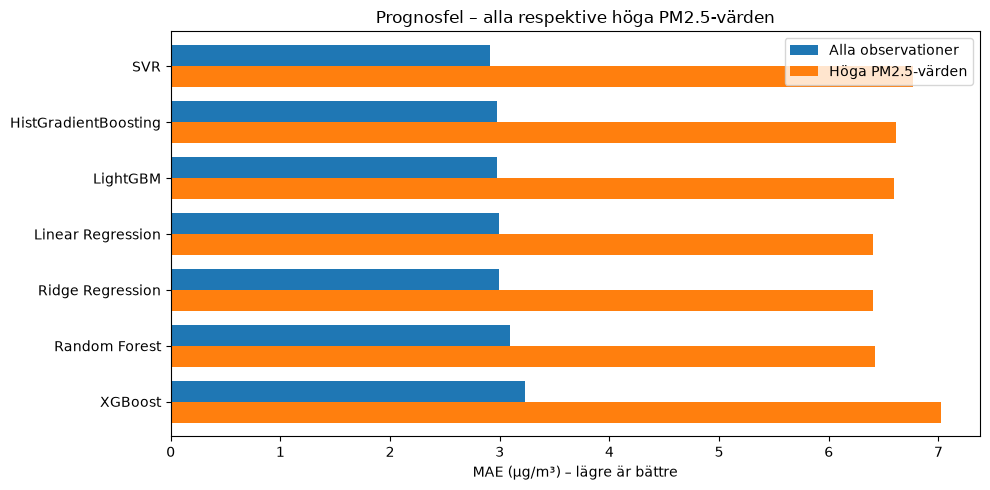

In [10]:
plot_df = results_df.set_index("Modell")[["Validation MAE", "Validation High PM2.5 MAE"]].sort_values("Validation MAE")
ax = plot_df.plot(kind="barh", figsize=(10, 5), width=0.75)
ax.invert_yaxis()
ax.set_xlabel("MAE (µg/m³) – lägre är bättre")
ax.set_ylabel("")
ax.set_title("Prognosfel – alla respektive höga PM2.5-värden")
ax.legend(["Alla observationer", "Höga PM2.5-värden"])
plt.tight_layout()
plt.show()

### Sammanfattande resultat

SVR har lägst generell MAE (2,91 µg/m³), medan Linear Regression och Ridge presterar bäst vid höga PM2.5-koncentrationer (MAE 6,40 µg/m³). Samtliga modeller uppvisar negativ Bias vid höga koncentrationer, vilket visar på systematisk underskattning.

**Skillnaden visar att modellernas inbördes rangordning påverkas av vilka koncentrationer som prioriteras.**

För att bedöma om modellerna faktiskt tillför något jämförs de därefter med persistence baseline.

## 3. Är modellerna bättre än baseline? 

För att bedöma modellernas prognosprecision jämförs deras MAE med persistence baseline, som antar oförändrad PM2.5-koncentration sex timmar framåt. Jämförelsen görs både generellt och vid höga koncentrationer.

In [12]:
baseline_train_metrics, baseline_val_metrics = persistence_baseline(
    X_train, y_train, X_val, y_val
)
baseline_df = pd.DataFrame(
    [baseline_train_metrics, baseline_val_metrics],
    index=["Träning", "Validering"]
)
display(baseline_df.round(3))

,MAE,RMSE,R2,Bias,High PM2.5 MAE,High PM2.5 Bias,High PM2.5 Count
Träning,2.621,4.177,0.565,-0.020,6.448,-3.04,2156
Validering,3.108,4.703,0.677,0.017,6.122,-2.00,616


### 3.1 Förbättring i MAE jämfört med baseline

En positiv procentsats innebär lägre MAE än baseline; en negativ procentsats innebär högre MAE. Baseline visas som egen referensrad.

In [14]:
comparison_pct = results_df[["Modell", "Validation MAE", "Validation High PM2.5 MAE"]].copy()
comparison_pct = pd.concat([
    comparison_pct,
    pd.DataFrame([{
        "Modell": "Persistence baseline",
        "Validation MAE": baseline_val_metrics["MAE"],
        "Validation High PM2.5 MAE": baseline_val_metrics["High PM2.5 MAE"],
    }])
], ignore_index=True)
comparison_pct["Förbättring totalt (%)"] = 100 * (
    baseline_val_metrics["MAE"] - comparison_pct["Validation MAE"]
) / baseline_val_metrics["MAE"]
comparison_pct["Förbättring höga (%)"] = 100 * (
    baseline_val_metrics["High PM2.5 MAE"] - comparison_pct["Validation High PM2.5 MAE"]
) / baseline_val_metrics["High PM2.5 MAE"]
display(comparison_pct.sort_values("Validation MAE").reset_index(drop=True).round(2))

,Modell,Validation MAE,Validation High PM2.5 MAE,Förbättring totalt (%),Förbättring höga (%)
0,SVR,2.91,6.76,6.38,-10.49
1,HistGradientBoosting,2.97,6.61,4.43,-7.98
2,LightGBM,2.98,6.59,4.20,-7.66
3,Linear Regression,2.99,6.40,3.78,-4.52
4,Ridge Regression,2.99,6.40,3.78,-4.53
5,Random Forest,3.10,6.42,0.33,-4.88
6,Persistence baseline,3.11,6.12,0.00,0.00
7,XGBoost,3.23,7.03,-3.92,-14.79


SVR förbättrar generell MAE med cirka 6,4 % jämfört med persistence baseline. Vid höga PM2.5-koncentrationer presterar däremot baseline bättre än samtliga maskininlärningsmodeller.

Resultaten motiverar en närmare analys av modellernas prognosfel, särskilt om de systematiskt över- eller underskattar vissa koncentrationer.

## 4. Finns det systematiska prognosfel?

Ett Bias nära noll behöver inte innebära att modellen saknar systematiska fel, eftersom över- och underskattningar kan ta ut varandra.

Vi undersöker därför sambandet mellan verkliga och förutsagda värden och beräknar Bias separat för observationer under och över gränsen för höga PM2.5-koncentrationer.

### 4.1 Hur skiljer sig prognoserna från de verkliga värdena?

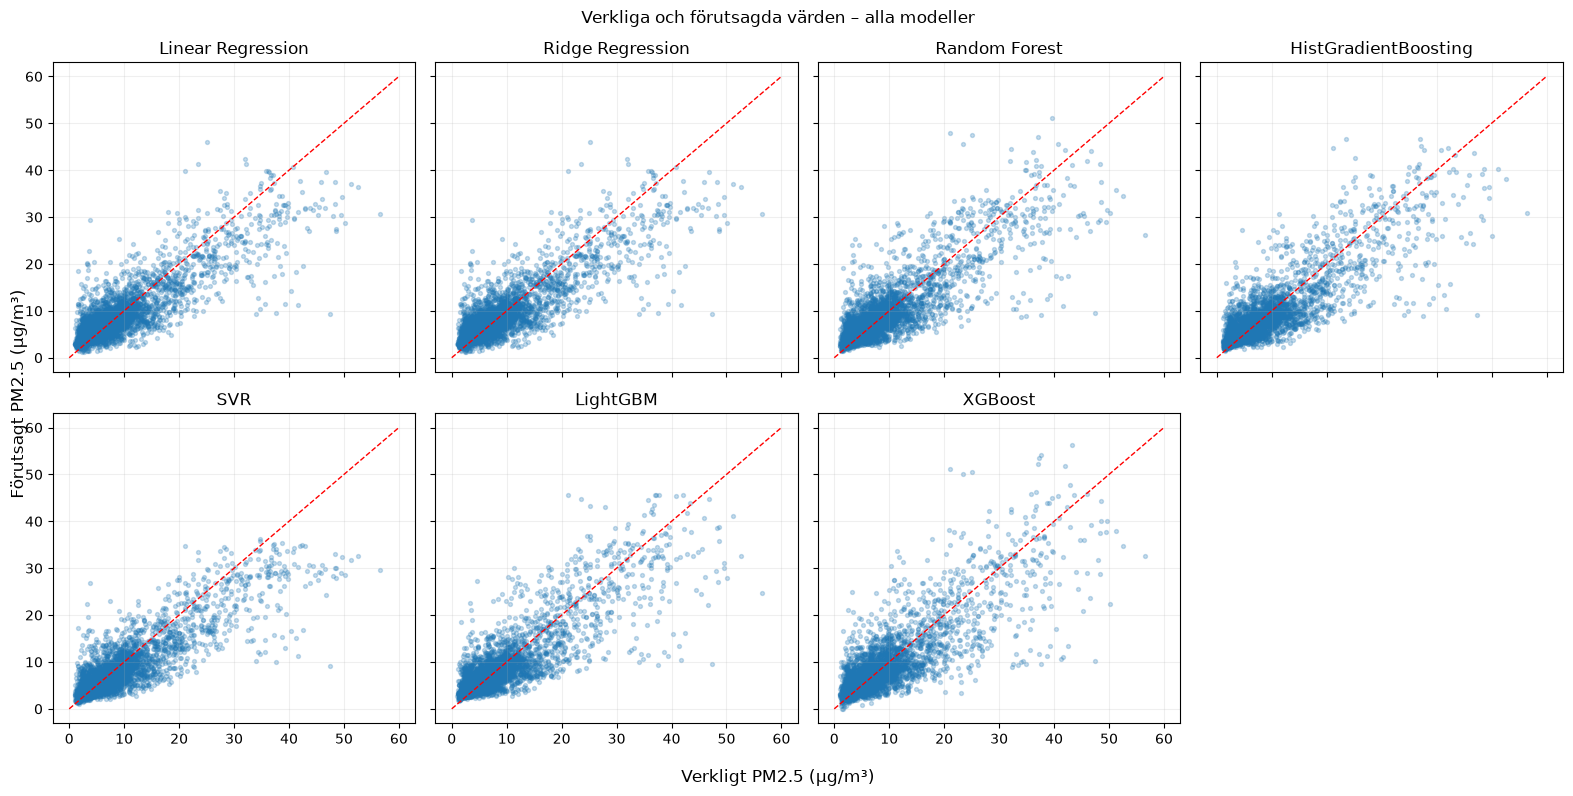

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
max_value = max(float(y_val.max()), 60)
for ax, (namn, modell) in zip(axes.flat, trained_models.items()):
    y_pred = modell.predict(X_val)
    ax.scatter(y_val, y_pred, alpha=0.25, s=8)
    ax.plot([0, max_value], [0, max_value], "r--", linewidth=1)
    ax.set_title(namn)
    ax.grid(alpha=0.2)
axes.flat[-1].axis("off")
fig.supxlabel("Verkligt PM2.5 (µg/m³)")
fig.supylabel("Förutsagt PM2.5 (µg/m³)")
fig.suptitle("Verkliga och förutsagda värden – alla modeller")
plt.tight_layout()
plt.show()

Spridningsdiagrammen visar ett liknande mönster för samtliga modeller. Låga PM2.5-koncentrationer tenderar att överskattas, medan höga koncentrationer underskattas.

Detta tyder på att modellerna har svårt att fånga variationen i de högsta koncentrationerna.

### 4.2 Bekräftas mönstret av Bias?

In [16]:
low_mask = y_val.to_numpy() < high_pm25_threshold
high_mask = ~low_mask
bias_rows = []
for namn, modell in trained_models.items():
    error = np.asarray(modell.predict(X_val)) - y_val.to_numpy()
    bias_rows.append({
        "Modell": namn,
        "Bias under tröskel": error[low_mask].mean(),
        "Bias höga värden": error[high_mask].mean(),
        "Bias totalt": error.mean(),
    })
bias_rows.append({
    "Modell": "Persistence baseline",
    "Bias under tröskel": (X_val["pm25"].to_numpy() - y_val.to_numpy())[low_mask].mean(),
    "Bias höga värden": baseline_val_metrics["High PM2.5 Bias"],
    "Bias totalt": baseline_val_metrics["Bias"],
})
display(pd.DataFrame(bias_rows).round(3))

,Modell,Bias under tröskel,Bias höga värden,Bias totalt
0,Linear Regression,0.837,-4.902,-0.155
1,Ridge Regression,0.837,-4.902,-0.155
2,Random Forest,0.931,-3.705,0.129
3,HistGradientBoosting,0.636,-4.106,-0.184
4,SVR,0.223,-5.784,-0.816
5,LightGBM,0.654,-3.809,-0.118
6,XGBoost,0.744,-3.968,-0.071
7,Persistence baseline,0.439,-2.000,0.017


### Tolkning av Bias

Samtliga modeller uppvisar positiv Bias under tröskelvärdet och negativ Bias vid höga PM2.5-koncentrationer. Detta bekräftar mönstret från spridningsdiagrammen: lägre koncentrationer tenderar att överskattas och höga att underskattas.

SVR har störst underskattning vid höga koncentrationer (−5,784 µg/m³), medan Random Forest har lägst bland ML-modellerna (−3,705 µg/m³). Persistence baseline uppvisar minst underskattning (−2,000 µg/m³).

Trots detta ligger totalt Bias nära noll för flera modeller, exempelvis XGBoost (−0,071) och LightGBM (−0,118). Det visar att över- och underskattningar delvis tar ut varandra och att ett lågt totalt Bias kan dölja systematiska prognosfel.

## 5. Hur påverkas modellvalet om höga PM2.5-värden prioriteras?

Tidigare resultat visar att modellen med lägst generell MAE inte nödvändigtvis presterar bäst vid höga koncentrationer.

För att undersöka hur detta påverkar modellvalet beräknas en viktad poäng där generell MAE och MAE vid höga koncentrationer ges olika betydelse. Måtten normaliseras mot persistence baseline för att möjliggöra en jämförbar viktning.

### 5.1 Viktad modelljämförelse

Vi undersöker ett scenario där generell MAE viktas till 60 % och MAE vid höga PM2.5-koncentrationer till 40 %. Måtten normaliseras mot persistence baseline så att de kan vägas samman.

Lägre poäng innebär bättre resultat, och persistence baseline får poängen 1. Viktningen är ett exempel för att undersöka hur modellvalet påverkas, inte ett fastställt urvalskriterium.

In [20]:
vikt_hoga = 0.40  # ändra om projektets prioriteringar motiverar en annan vikt
ranking_df = comparison_pct[["Modell", "Validation MAE", "Validation High PM2.5 MAE"]].copy()

ranking_df["Viktad poäng"] = (
    (1 - vikt_hoga) * ranking_df["Validation MAE"] / baseline_val_metrics["MAE"]
    + vikt_hoga * ranking_df["Validation High PM2.5 MAE"] / baseline_val_metrics["High PM2.5 MAE"]
)
display(ranking_df.sort_values("Viktad poäng").reset_index(drop=True).round(3))

,Modell,Validation MAE,Validation High PM2.5 MAE,Viktad poäng
0,Linear Regression,2.991,6.399,0.995
1,Ridge Regression,2.991,6.399,0.995
2,Persistence baseline,3.108,6.122,1.000
3,SVR,2.910,6.764,1.004
4,HistGradientBoosting,2.971,6.611,1.005
5,LightGBM,2.978,6.591,1.005
6,Random Forest,3.098,6.421,1.018
7,XGBoost,3.230,7.027,1.083


Vid viktningen 60/40 får Linear Regression och Ridge lägst sammanvägd poäng (cirka 0,995), tätt följda av persistence baseline (1,000).

Skillnaderna är små, vilket visar att modellvalet inte är självklart. Resultatet beror på hur generell prognosprecision och precision vid höga koncentrationer prioriteras.

### 5.2 Hur känsligt är modellvalet för viktningen?

För att undersöka hur känsligt modellvalet är varierar vi vikten för höga PM2.5-koncentrationer mellan 0 och 100 %. Syftet är att se om samma modell presterar bäst oavsett prioritering eller om valet av champion förändras.

In [21]:
sensitivity_rows = []

for vikt_hoga in [0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]:

    poang = (
        (1 - vikt_hoga)
        * ranking_df["Validation MAE"]
        / baseline_val_metrics["MAE"]
        +
        vikt_hoga
        * ranking_df["Validation High PM2.5 MAE"]
        / baseline_val_metrics["High PM2.5 MAE"]
    )

    lagsta_poang = poang.min()

    vinnare = ranking_df.loc[
        np.isclose(poang, lagsta_poang, atol=1e-5),
        "Modell"
    ].tolist()

    sensitivity_rows.append({
        "Vikt höga (%)": int(vikt_hoga * 100),
        "Bästa modell": " / ".join(vinnare),
        "Viktad poäng": lagsta_poang
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)

display(sensitivity_df.round(3))

,Vikt höga (%),Bästa modell,Viktad poäng
0,0,SVR,0.936
1,20,SVR,0.970
2,40,Linear Regression / Ridge Regression,0.995
3,50,Persistence baseline,1.000
4,60,Persistence baseline,1.000
5,80,Persistence baseline,1.000
6,100,Persistence baseline,1.000


Resultaten visar att modellvalet är känsligt för viktningen. När generell MAE prioriteras väljs SVR, medan Linear Regression och Ridge presterar bäst vid 40 % vikt för höga koncentrationer. Vid 50 % eller högre vikt blir persistence baseline det bästa alternativet.

Att en enkel baseline presterar bäst när höga koncentrationer prioriteras stärker bilden av att maskininlärningsmodellerna har svårt att förutsäga dessa värden.

Det finns därmed ingen entydig champion. Modellvalet beror på hur stor betydelse prognosprecision vid höga PM2.5-koncentrationer ska ges.

## 6. Bör flera utvärderingsmått vägas samman?

Hittills har modellvalet främst utgått från MAE. Den tidigare jämförelsen visar dock att modellerna även skiljer sig åt i RMSE och Bias, och den fördjupade analysen har visat att totalt Bias kan dölja systematiska prognosfel.

Frågan är därför om en sammanvägning av flera mått skulle ge ett bättre underlag för val av champion-modell.

### 6.1 Vad tillför de olika måtten?

De tre måtten belyser olika aspekter av modellernas prognosfel:

- **MAE** visar den genomsnittliga storleken på prognosfelen och är lätt att tolka i µg/m³.
- **RMSE** ger större betydelse åt stora prognosfel. Detta är särskilt intressant eftersom spridningsdiagrammen visade att felen tenderar att öka vid höga PM2.5-koncentrationer.
- **Bias** visar om modellen tenderar att över- eller underskatta de verkliga värdena. Ett Bias nära noll kan dock vara missvisande om positiva och negativa fel tar ut varandra.

Måtten kompletterar därmed varandra. MAE och RMSE beskriver prognosfelens storlek, medan Bias beskriver deras riktning.

### 6.2 Bör måtten vägas samman?

Eftersom RMSE ger större betydelse åt stora prognosfel undersöker vi om modellernas rangordning förändras när både MAE och RMSE används vid modellvalet.

Vi beräknar en sammanvägd poäng där måtten viktas lika (50/50) och normaliseras mot persistence baseline. Lägre poäng innebär bättre resultat.

Bias inkluderas inte eftersom den tidigare analysen visade att totalt Bias kan dölja systematiska fel vid olika koncentrationsnivåer.

In [23]:
# Jämför modellval baserat på MAE respektive MAE + RMSE

metric_df = results_df[
    ["Modell", "Validation MAE", "Validation RMSE"]
].copy()

baseline_row = pd.DataFrame([{
    "Modell": "Persistence baseline",
    "Validation MAE": baseline_val_metrics["MAE"],
    "Validation RMSE": baseline_val_metrics["RMSE"]
}])

metric_df = pd.concat(
    [metric_df, baseline_row],
    ignore_index=True
)

# Normalisera mot persistence baseline
metric_df["MAE-poäng"] = (
    metric_df["Validation MAE"] / baseline_val_metrics["MAE"]
)

metric_df["MAE + RMSE-poäng"] = (
    0.5 * metric_df["Validation MAE"] / baseline_val_metrics["MAE"]
    + 0.5 * metric_df["Validation RMSE"] / baseline_val_metrics["RMSE"]
)

# Jämför rangordning
metric_df["Rang MAE"] = metric_df["MAE-poäng"].rank(
    method="min"
).astype(int)

metric_df["Rang MAE + RMSE"] = metric_df["MAE + RMSE-poäng"].rank(
    method="min"
).astype(int)

display(
    metric_df[
        ["Modell", "MAE-poäng", "MAE + RMSE-poäng",
         "Rang MAE", "Rang MAE + RMSE"]
    ]
    .sort_values("Rang MAE + RMSE")
    .round(3)
)

,Modell,MAE-poäng,MAE + RMSE-poäng,Rang MAE,Rang MAE + RMSE
0,SVR,0.936,0.941,1,1
3,Linear Regression,0.962,0.955,4,2
4,Ridge Regression,0.962,0.955,5,3
1,HistGradientBoosting,0.956,0.962,2,4
2,LightGBM,0.958,0.965,3,5
5,Random Forest,0.997,0.992,6,6
7,Persistence baseline,1.000,1.000,7,7
6,XGBoost,1.039,1.044,8,8


För att undersöka hur känsligt resultatet är för viktningen varierar vi RMSE:s andel från 0 till 100 %. På så sätt kan vi se om valet av champion påverkas av hur stor betydelse vi ger stora prognosfel.

In [24]:
sensitivity_metrics = []

for vikt_rmse in [0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]:

    poang = (
        (1 - vikt_rmse) * metric_df["MAE-poäng"]
        + vikt_rmse
        * metric_df["Validation RMSE"]
        / baseline_val_metrics["RMSE"]
    )

    lagsta_poang = poang.min()

    vinnare = metric_df.loc[
        np.isclose(poang, lagsta_poang, atol=1e-5),
        "Modell"
    ].tolist()

    sensitivity_metrics.append({
        "Vikt RMSE (%)": int(vikt_rmse * 100),
        "Bästa modell": " / ".join(vinnare),
        "Viktad poäng": lagsta_poang
    })

sensitivity_metrics_df = pd.DataFrame(sensitivity_metrics)

display(sensitivity_metrics_df.round(3))

,Vikt RMSE (%),Bästa modell,Viktad poäng
0,0,SVR,0.936
1,20,SVR,0.938
2,40,SVR,0.940
3,50,SVR,0.941
4,60,SVR,0.943
5,80,SVR,0.945
6,100,SVR,0.947


### Tolkning av resultatet

När MAE och RMSE viktas lika behåller SVR förstaplatsen. Rangordningen förändras däremot för flera andra modeller. Linear Regression och Ridge förbättrar sina placeringar, medan HistGradientBoosting och LightGBM tappar.

Känslighetsanalysen visar att SVR förblir bäst även när RMSE:s vikt varierar från 0 till 100 %. Valet av champion är därmed stabilt oavsett hur dessa två mått viktas i den undersökta jämförelsen.

Detta skiljer sig från analysen i avsnitt 5, där champion-valet förändrades när höga PM2.5-koncentrationer prioriterades. Resultaten tyder därför på att prioriteringen av höga koncentrationer har större betydelse för modellvalet än hur generell MAE och RMSE viktas mot varandra.

## 7. Slutsatser och rekommendationer

Den fördjupade analysen visar att samtliga ML-modeller har svårt att förutsäga höga PM2.5-koncentrationer och tenderar att underskatta dessa. Persistence baseline presterar dessutom bättre vid höga värden. Känslighetsanalysen visar att valet av champion påverkas av hur dessa koncentrationer prioriteras.

SVR har samtidigt bäst generell prognosprecision (MAE 2,91 µg/m³) och behåller förstaplatsen oavsett hur generell MAE och RMSE viktas.

### Rekommendation

Vi rekommenderar att **MAE används som huvudmått**, med RMSE, Bias och MAE vid höga koncentrationer som kompletterande mått.

Vi rekommenderar inte att kombinera samtliga mått i ytterligare en viktad formel, eftersom måtten delvis överlappar och viktningen riskerar att bli godtycklig.

**SVR är den starkaste kandidaten utifrån generell prognosprecision**, men om höga koncentrationer prioriteras bör även persistence baseline övervägas.

När champion har valts bör den utvärderas på den separata testperioden.

### 7.2 Kontroll av modellval med MAE och R²

För att undersöka om valet av utvärderingsmått påverkar modellurvalet genomfördes ett separat experiment med `compare_champion_metrics.py`. Samma kandidatmodeller tränades och utvärderades med MAE respektive R² som urvalskriterium. Den bästa kandidaten jämfördes därefter med den befintliga championmodellen på testdata.

**Resultat från körningen den 26 oktober 2026**

| Urvalsmått | Bästa kandidat | Valideringsresultat | Slutlig champion |
|---|---|---:|---|
| MAE | SVR | 2,6850 µg/m³ | SVR vanlig (T+6) |
| R² | SVR | 0,7143 | SVR vanlig (T+6) |

**Jämförelse på testdata (2 595 observationer)**

| Mått | Ny SVR | Befintlig champion |
|---|---:|---:|
| MAE | 1,5240 | 1,5211 |
| RMSE | 2,1933 | 2,1900 |
| R² | 0,5929 | 0,5941 |
| Bias | 0,0442 | 0,0403 |

Båda urvalsmåtten valde SVR som bästa kandidat och den befintliga championmodellen behölls vid båda jämförelserna. Skillnaden i MAE på testdata var endast cirka 0,0029 µg/m³.

Resultatet visar att valet mellan MAE och R² inte förändrade modellvalet i detta experiment. Det innebär däremot inte att måtten generellt är utbytbara eller att den befintliga modellen är betydligt bättre i praktiken.

### 7.3 Val av utvärderingsmått i modellpipen

Analysen motiverar MAE som primärt mått vid jämförelse av kandidatmodeller, eftersom det ger ett direkt tolkningsbart prognosfel i µg/m³. Måttet gör det möjligt att välja den modell som har lägst genomsnittlig prognosavvikelse. RMSE, R², Bias och MAE vid höga PM2.5-koncentrationer används som kompletterande mått.

En separat jämförelse av MAE och R² som urvalskriterier visade att båda valde SVR som bästa kandidat och att den befintliga championmodellen behölls oavsett mått.

Modellpipen använder därför MAE vid kandidatvalet och R² vid jämförelsen med befintlig champion. **Syftet med att använda olika mått är att skilja mellan två olika urvalsbeslut.** Vid kandidatvalet prioriteras ett lågt genomsnittligt prognosfel, medan championvalet fokuserar på om den nya modellen förbättrar förmågan att beskriva variationen i PM2.5 jämfört med den befintliga modellen.

Kombinationen innebär att kandidatmodellerna väljs utifrån prognosernas genomsnittliga träffsäkerhet, medan en ny champion endast utses om den uppvisar ett högre R² än den befintliga championmodellen.